# 4.5 Analisis Spasial dan Network Overlay

**Tujuan penelitian 3.** Mengintegrasikan model IRIO Network dengan analisis spasial dalam kerangka *network overlay* untuk menghasilkan representasi spillover yang mencerminkan keterkaitan struktural ekonomi sekaligus kedekatan geografis antarwilayah.

Notebook ini melanjutkan hasil Tujuan 2 (`E1_Input_Analisis_Spasial.csv`, `C1_Spillover_Interregional.csv`). Alurnya:

| Bagian | Isi |
|---|---|
| 0 | Persiapan |
| 1 | Penyusunan matriks bobot spasial (W) dari konektivitas udara |
| 2 | Autokorelasi spasial global (Moran's I) |
| 3 | Autokorelasi spasial lokal (LISA) dan pemetaan klaster |
| 4 | Uji independensi jaringan struktural dan jaringan geografis |
| 5 | Network overlay: tipologi provinsi dan visualisasi gabungan |
| 6 | Ekspor |

**Prinsip dasar.** Dua jaringan yang berbeda mekanismenya diuji secara terpisah lalu digabung. Jaringan pertama adalah keterkaitan struktural (Koef_Struktural_L, hasil Tujuan 2, berbasis transaksi input-output). Jaringan kedua adalah kedekatan geografis (matriks bobot W, berbasis konektivitas udara). Logika pengujian independensi ini mengikuti Acemoglu, Akcigit, & Kerr (2016), yang menunjukkan korelasi rendah (0,108–0,275) antara jaringan input-output dan jaringan kolokasi geografis pada level industri di Amerika Serikat, sehingga keduanya dianggap sebagai kanal propagasi yang saling melengkapi, bukan saling menggantikan. Penelitian ini mengadaptasi logika tersebut ke level wilayah (bukan pasangan industri) menggunakan kerangka statistik spasial (Moran's I dan LISA), karena satuan analisisnya adalah provinsi.

---
## Bagian 0 — Persiapan

In [ ]:
import subprocess, sys
for pkg in ['esda==2.10.0', 'libpysal==4.13.0', 'splot', 'geopandas', 'mapclassify']:
    subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

import os, warnings
import numpy as np
np.random.seed(12345)
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch, FancyArrowPatch
from matplotlib.lines import Line2D
import geopandas as gpd
import requests
from scipy import stats
from libpysal.weights import full2W
from esda.moran import Moran, Moran_Local
warnings.filterwarnings('ignore')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/[01] Tugas-Atikah-STIS/[01] Skripsi Atikah/Data/'
except ImportError:
    BASE = os.environ.get('SKRIPSI_DATA', './Data/')

F_E1 = BASE + 'csv_output/E1_Input_Analisis_Spasial.csv'
F_C1 = BASE + 'csv_output/C1_Spillover_Interregional.csv'
F_W  = BASE + 'matriks_konektivitas_spasial_transit.xlsx'
OUT_DIR = BASE + '09. Analisis Spatial+Network Overlay/'
FIG_DIR = OUT_DIR + 'figur/'
for d in (OUT_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

for f in (F_E1, F_C1, F_W):
    assert os.path.exists(f), f'Tidak ditemukan: {f}'
    print('OK :', os.path.basename(f))

NAMA_BALI = 'Bali'
SUMBER_IRIO = 'Simulasi IRIO Tujuan 2, diolah.'
SUMBER_W    = 'Estimasi konektivitas udara berbasis waktu tempuh dan jumlah transit, diolah.'

Mounted at /content/drive
OK : E1_Input_Analisis_Spasial.csv
OK : C1_Spillover_Interregional.csv
OK : matriks_konektivitas_spasial_transit.xlsx


In [ ]:
MM = 1 / 25.4
LEBAR = 160 * MM
SERTAKAN_JUDUL  = False   # judul ditulis di Word
SERTAKAN_SUMBER = False   # sumber dan catatan ditulis di Word

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 8,
    'axes.titlesize': 8.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6,
    'legend.frameon': False, 'figure.dpi': 130,
    'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.08, 'pdf.fonttype': 42,
})

C_HH, C_LH, C_HL, C_LL, C_NS, C_BALI = '#d73027', '#4575b4', '#fc8d59', '#91bfdb', '#d9d9d9', '#8c564b'
WARNA_KUADRAN = {'HH': C_HH, 'LH': C_LH, 'HL': C_HL, 'LL': C_LL, 'Not Significant': C_NS}

def fmt(x, d=2):
    return f'{x:,.{d}f}'.replace(',', '#').replace('.', ',').replace('#', '.')

DAFTAR_GAMBAR = []
def simpan(fig, kode, judul, sumber=SUMBER_IRIO, catatan=None):
    if SERTAKAN_JUDUL:
        fig.suptitle(judul, x=0.01, ha='left', fontsize=9.5, fontweight='bold')
    if SERTAKAN_SUMBER:
        teks = f'Sumber: {sumber}' + (f'\nCatatan: {catatan}' if catatan else '')
        fig.text(0.01, -0.005, teks, ha='left', va='top', fontsize=6.6, color='#555555',
                 transform=fig.transFigure)
    for ext in ('png', 'pdf'):
        fig.savefig(f'{FIG_DIR}{kode}.{ext}')
    plt.show()
    DAFTAR_GAMBAR.append({'No': len(DAFTAR_GAMBAR) + 1, 'Berkas': kode, 'Judul': judul,
                          'Sumber': sumber, 'Catatan': catatan or ''})
    print(f'Gambar {len(DAFTAR_GAMBAR)} tersimpan -> figur/{kode}.png | .pdf')
print('Gaya gambar siap.')

def atur_cbar_linier(cb, vmin, vmax, n=5, desimal=2):
    t = np.linspace(vmin, vmax, n)
    cb.set_ticks(t)
    cb.set_ticklabels([fmt(v, desimal) for v in t])
    cb.ax.tick_params(labelsize=6.5)
print('Fungsi atur siap.')

Gaya gambar siap.
Fungsi atur siap.


### 0.1 Memuat hasil Tujuan 2

In [ ]:
df_e1 = pd.read_csv(F_E1)
df_c1 = pd.read_csv(F_C1)
if 'Output_triliun' not in df_e1.columns:
    F_A1 = BASE + 'csv_output/A1_Dampak_per_Provinsi.csv'
    df_a1 = pd.read_csv(F_A1)[['Provinsi', 'Output_triliun', 'Intensitas_pct']]
    df_e1 = df_e1.merge(df_a1, on='Provinsi', how='left')
    assert df_e1['Output_triliun'].notna().all(), 'Gagal menggabungkan Output_triliun dari A1'
prov_list = df_e1['Provinsi'].str.strip().tolist()
N_PROV = len(prov_list)
idx_bali = prov_list.index(NAMA_BALI)

assert N_PROV == 34, f'Jumlah provinsi {N_PROV}, seharusnya 34'
print(f'E1: {len(df_e1)} provinsi, kolom: {list(df_e1.columns)}')
df_e1[['Provinsi', 'Dx_triliun', 'Koef_Struktural_L']].head()

E1: 34 provinsi, kolom: ['Provinsi', 'Dx_juta', 'Dx_triliun', 'Lat', 'Lon', 'Tipe', 'Koef_Struktural_L', 'Spillover_triliun', 'Output_triliun', 'Intensitas_pct']


,Provinsi,Dx_triliun,Koef_Struktural_L
0,Aceh,-0.0785,0.022518
1,Sumatera Utara,-0.6442,0.101384
2,Sumatera Barat,-0.0979,0.022476
3,Riau,-1.0827,0.171228
4,Jambi,-0.2933,0.105703


---
## Bagian 1 — Penyusunan Matriks Bobot Spasial (W)

### 1.1 Prinsip konektivitas udara sebagai ukuran kedekatan

Kedekatan antarwilayah pada penelitian ini diukur melalui konektivitas penerbangan, bukan jarak fisik antar-ibu kota provinsi. Pilihan ini didasarkan pada dua alasan. Pertama, Indonesia adalah negara kepulauan, sehingga matriks ketetanggaan fisik (*contiguity*) akan menghasilkan banyak provinsi yang terisolasi tanpa tetangga darat. Kedua, dan lebih penting, penelitian ini mengenai pariwisata, dan wisatawan maupun pelaku bisnis bergerak melalui jaringan penerbangan, bukan garis lurus di peta. Bobot mentah dirumuskan sebagai:

$$w_{ij} = \frac{1}{T_{ij}^{\alpha} \times (1+transit_{ij})^{\beta}}$$

dengan $T_{ij}$ waktu tempuh total (termasuk waktu tunggu transit) dalam jam, dan $transit_{ij}$ jumlah transit. Nilai $\alpha=1,\ \beta=1$ dipakai pada penelitian ini, sehingga rute dengan transit dikenakan penalti tambahan di atas waktu tempuhnya sendiri: satu kali transit membagi bobot dengan 2, dua kali transit dengan 3, dan seterusnya. Bobot mentah kemudian dibakukan baris (*row-standardized*) sehingga jumlah tiap baris sama dengan satu.

### 1.2 Melengkapi pasangan yang belum tercatat

Sebagian pasangan provinsi belum tercatat konektivitasnya secara langsung karena tiketnya tidak tersedia sebagai satu itinerary gabungan. Untuk pasangan tersebut, waktu tempuh dihitung dari penjumlahan dua ruas penerbangan yang sudah tercatat, melalui kota transit yang relevan:

$$T_{i,j} = T_{i,\text{hub}} + T_{tunggu} + T_{\text{hub},j}$$

Dua kelompok pasangan yang dilengkapi dengan cara ini:

- **Blok Banten.** Bandara acuan Banten (Soekarno-Hatta) secara administratif identik dengan bandara acuan DKI Jakarta. Konektivitas Banten ke seluruh provinsi lain karena itu disamakan dengan konektivitas DKI Jakarta, ditambah satu pasangan Banten–DKI Jakarta dengan waktu tempuh darat singkat.
- **Sembilan pasangan Jawa Barat dan dua pasangan Kalimantan Utara/Gorontalo.** Dihitung melalui kota hub yang relevan (DKI Jakarta untuk Jawa Barat; Sulawesi Selatan untuk Kalimantan Utara–Gorontalo dan Gorontalo–Sulawesi Barat), dengan buffer waktu tunggu 3,5 jam karena tiketnya dibeli terpisah (bukan connecting time minimum untuk tiket tergabung).

Jumlah transit pasangan hasil penjumlahan ini dihitung sebagai jumlah transit kedua ruas ditambah satu (untuk perpindahan di kota hub itu sendiri).

In [ ]:
KOL = pd.read_excel(F_W, sheet_name='Input_Konektivitas', header=1)
KOL.columns = ['Provinsi_A', 'Provinsi_B', 'Jumlah_Transit', 'Waktu_Tempuh_jam', 'Sumber', 'Catatan']
RENAME_W = {'Kepulauan Riau': 'Kep. Riau'}
KOL['Provinsi_A'] = KOL['Provinsi_A'].replace(RENAME_W)
KOL['Provinsi_B'] = KOL['Provinsi_B'].replace(RENAME_W)
BUFFER_TUNGGU = 3.5   # jam, buffer aman untuk tiket yang dibeli terpisah (self-connect)

def cari(a, b):
    r = KOL[((KOL.Provinsi_A == a) & (KOL.Provinsi_B == b)) |
            ((KOL.Provinsi_A == b) & (KOL.Provinsi_B == a))]
    if len(r) == 0 or pd.isna(r.iloc[0]['Waktu_Tempuh_jam']):
        return None
    return float(r.iloc[0]['Jumlah_Transit']), float(r.iloc[0]['Waktu_Tempuh_jam'])

def sambung(a, hub, b, sumber_label):
    ra, rb = cari(a, hub), cari(hub, b)
    assert ra is not None and rb is not None, f'Ruas {a}-{hub} atau {hub}-{b} belum tercatat'
    transit = ra[0] + rb[0] + 1
    waktu = ra[1] + BUFFER_TUNGGU + rb[1]
    return {'Provinsi_A': a, 'Provinsi_B': b, 'Jumlah_Transit': transit, 'Waktu_Tempuh_jam': round(waktu, 3),
            'Sumber': f'Estimasi mandiri: {a}-{hub} + buffer {BUFFER_TUNGGU} jam + {hub}-{b} ({sumber_label})',
            'Catatan': 'Dihitung, tiket tidak tergabung'}

tambahan = []

# --- Blok Banten: samakan dengan DKI Jakarta ---
prov_lain = [p for p in prov_list if p not in ('Banten', 'DKI Jakarta')]
for p in prov_lain:
    rj = cari('DKI Jakarta', p)
    assert rj is not None, f'DKI Jakarta-{p} belum tercatat, tidak bisa menyalin ke Banten'
    tambahan.append({'Provinsi_A': 'Banten', 'Provinsi_B': p, 'Jumlah_Transit': rj[0], 'Waktu_Tempuh_jam': rj[1],
                     'Sumber': 'Disamakan dengan DKI Jakarta (bandara acuan identik, CGK)', 'Catatan': ''})
tambahan.append({'Provinsi_A': 'Banten', 'Provinsi_B': 'DKI Jakarta', 'Jumlah_Transit': 0, 'Waktu_Tempuh_jam': 0.5,
                 'Sumber': 'Estimasi jarak darat Tangerang-Jakarta', 'Catatan': ''})

# --- Sembilan pasangan Jawa Barat, disambung lewat DKI Jakarta ---
for p in ['Jambi', 'Bengkulu', 'Kep. Bangka Belitung', 'Kep. Riau', 'Jawa Tengah',
          'DI Yogyakarta', 'Kalimantan Tengah', 'Kalimantan Utara', 'Sulawesi Tengah']:
    tambahan.append(sambung('Jawa Barat', 'DKI Jakarta', p, 'Traveloka per ruas'))

# --- Dua pasangan Kalimantan Utara / Gorontalo, disambung lewat Sulawesi Selatan (Makassar) ---
tambahan.append(sambung('Kalimantan Utara', 'Sulawesi Selatan', 'Gorontalo', 'Traveloka per ruas'))
tambahan.append(sambung('Gorontalo', 'Sulawesi Selatan', 'Sulawesi Barat', 'Traveloka per ruas'))

df_tambahan = pd.DataFrame(tambahan)
print(f'{len(df_tambahan)} pasangan dilengkapi:')
display(df_tambahan[['Provinsi_A', 'Provinsi_B', 'Jumlah_Transit', 'Waktu_Tempuh_jam']])

KOL_lengkap = pd.concat([KOL[KOL['Waktu_Tempuh_jam'].notna()], df_tambahan], ignore_index=True)
sisa_kosong = 561 - len(KOL_lengkap[KOL_lengkap['Waktu_Tempuh_jam'].notna()]['Provinsi_A'].index)
print(f'\\nTotal pasangan terisi: {KOL_lengkap["Waktu_Tempuh_jam"].notna().sum()} dari 561')

44 pasangan dilengkapi:


,Provinsi_A,Provinsi_B,Jumlah_Transit,Waktu_Tempuh_jam
0,Banten,Aceh,0.0,2.91777
1,Banten,Sumatera Utara,1.0,2.42000
2,Banten,Sumatera Barat,0.0,1.83000
3,Banten,Riau,1.0,1.75000
4,Banten,Jambi,1.0,1.33000
5,Banten,Sumatera Selatan,1.0,1.16700
6,Banten,Bengkulu,0.0,1.33000
7,Banten,Lampung,0.0,0.75000
8,Banten,Kep. Bangka Belitung,1.0,1.17000
9,Banten,Kep. Riau,0.0,1.66667


\nTotal pasangan terisi: 561 dari 561


### 1.3 Membentuk matriks W

Waktu tempuh dan jumlah transit disusun menjadi matriks 34×34 (diasumsikan simetris, sesuai konvensi pada berkas sumber), lalu bobot mentah dihitung dan dibakukan baris.

In [ ]:
alpha, beta = 1, 1   # sesuai Matrix_Bobot sel B1, B2 pada berkas sumber

T = np.full((N_PROV, N_PROV), np.nan)
TR = np.full((N_PROV, N_PROV), np.nan)
idx = {p: i for i, p in enumerate(prov_list)}
for _, r in KOL_lengkap.iterrows():
    if r['Provinsi_A'] not in idx or r['Provinsi_B'] not in idx:
        continue
    i, j = idx[r['Provinsi_A']], idx[r['Provinsi_B']]
    T[i, j] = T[j, i] = r['Waktu_Tempuh_jam']
    TR[i, j] = TR[j, i] = r['Jumlah_Transit']
np.fill_diagonal(T, np.nan)

assert np.isnan(T).sum() == N_PROV, f'Masih ada {np.isnan(T).sum() - N_PROV} pasangan kosong di luar diagonal'

W_raw = np.where(np.isnan(T), 0, 1 / (np.where(T == 0, np.nan, T) ** alpha * (1 + TR) ** beta))
W_raw = np.nan_to_num(W_raw, nan=1 / 0.25)   # T=0 (Banten-Jakarta): bobot besar, setara T~0.25 jam
np.fill_diagonal(W_raw, 0)

baris_sum = W_raw.sum(axis=1)
assert (baris_sum > 0).all(), 'Ada provinsi tanpa satu pun koneksi (pulau terisolasi)'
W = W_raw / baris_sum[:, None]

print(f'Rata-rata jumlah tetangga (bobot > 0): {(W > 0).sum(axis=1).mean():.2f}')
print(f'Jumlah baris tidak sama dengan 1 (harus 0): {(np.abs(W.sum(1) - 1) > 1e-9).sum()}')
print(f'Provinsi terisolasi (harus 0): {(W.sum(1) == 0).sum()}')

Rata-rata jumlah tetangga (bobot > 0): 33.00
Jumlah baris tidak sama dengan 1 (harus 0): 0
Provinsi terisolasi (harus 0): 0


---
## Bagian 2 — Autokorelasi Spasial Global (Moran's I)

### 2.1 Pemilihan variabel: intensitas, bukan nominal

Uji Moran's I dilakukan pada **intensitas dampak** ($|\Delta x_r|$ terhadap output provinsi), bukan pada dampak nominal. Dampak nominal sebagian besar sudah ditentukan oleh ukuran ekonomi provinsi, dan `Koef_Struktural_L` pada layer struktural juga sudah mengukur besarnya keterkaitan ekonomi. Apabila variabel nominal yang diuji, klaster spasial yang ditemukan berisiko hanya menangkap ulang "provinsi besar berkumpul di Jawa" — informasi yang sudah terwakili oleh layer struktural, bukan temuan baru dari layer spasial. Intensitas menghilangkan efek ukuran tersebut, sehingga klaster yang ditemukan lebih murni mencerminkan pola spasial.

Provinsi Bali dikeluarkan dari pengujian karena berperan sebagai wilayah asal shock, bukan penerima spillover, dan intensitas dampaknya jauh melampaui provinsi lain sehingga akan mendominasi hasil jika diikutkan.

In [ ]:
np.random.seed(12345)

mask = np.array(prov_list) != NAMA_BALI
idx_keep = np.where(mask)[0]
W_sub = W[np.ix_(idx_keep, idx_keep)]
rs = W_sub.sum(axis=1)
W_sub = W_sub / rs[:, None]   # bakukan ulang baris setelah Bali dikeluarkan

df_sp = df_e1[mask].reset_index(drop=True).copy()
df_sp['Intensitas'] = df_sp['Dx_triliun'].abs() / df_sp['Output_triliun'] * 100

w_pysal = full2W(W_sub, ids=df_sp['Provinsi'].tolist())
w_pysal.transform = 'r'

attribut = df_sp['Intensitas'].values
moran_global = Moran(attribut, w_pysal, permutations=999)

print(f"Moran's I          : {moran_global.I:.4f}")
print(f'Expected I (E[I])  : {moran_global.EI:.4f}')
print(f'p-value (permutasi): {moran_global.p_sim:.4f}')
print(f'z-score            : {moran_global.z_sim:.4f}')

if moran_global.p_sim < 0.05:
    arah = 'positif (mengelompok)' if moran_global.I > moran_global.EI else 'negatif (menyebar)'
    print(f'-> Autokorelasi spasial global signifikan, arah {arah}.')
else:
    print('-> Autokorelasi spasial global tidak signifikan pada level 5 persen.')
    print('   Ini tidak menghalangi analisis lokal (LISA): pola global yang tidak signifikan')
    print('   dapat tetap menyembunyikan klaster lokal yang signifikan (Anselin, 1995),')
    print('   karena Moran global adalah rata-rata dari seluruh kontribusi lokal, sehingga')
    print('   klaster kuat di satu wilayah dapat saling meniadakan dengan pola acak di wilayah lain.')

Moran's I          : 0.0178
Expected I (E[I])  : -0.0312
p-value (permutasi): 0.1190
z-score            : 1.1431
-> Autokorelasi spasial global tidak signifikan pada level 5 persen.
   Ini tidak menghalangi analisis lokal (LISA): pola global yang tidak signifikan
   dapat tetap menyembunyikan klaster lokal yang signifikan (Anselin, 1995),
   karena Moran global adalah rata-rata dari seluruh kontribusi lokal, sehingga
   klaster kuat di satu wilayah dapat saling meniadakan dengan pola acak di wilayah lain.


### 2.2 Moran scatterplot

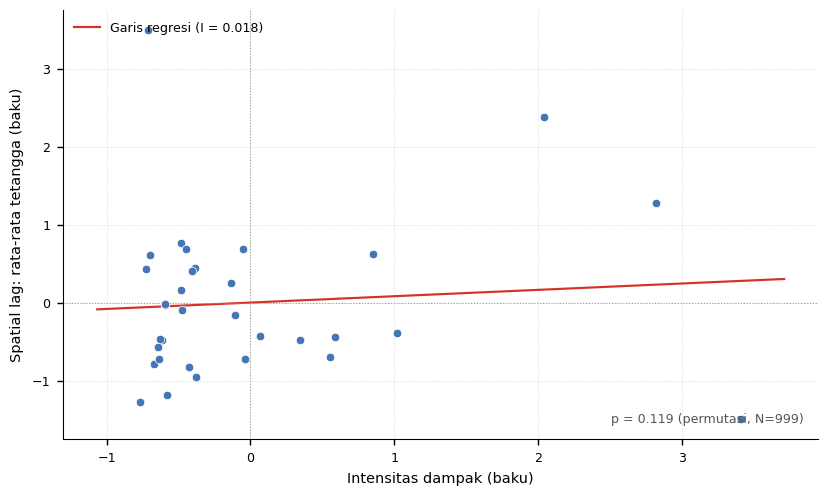

Gambar 2 tersimpan -> figur/4_5_01_moran_scatterplot.png | .pdf


In [ ]:
y = np.asarray(moran_global.y)
lag_y = np.asarray(moran_global.w.sparse @ y)
y_std = (y - y.mean()) / y.std()
lag_std = (lag_y - lag_y.mean()) / lag_y.std()

fig, ax = plt.subplots(figsize=(LEBAR, 95 * MM), layout='constrained')
ax.scatter(y_std, lag_std, s=22, color='#4575b4', edgecolor='white', lw=0.4, zorder=3)
b, a0 = np.polyfit(y_std, lag_std, 1)
xx = np.array([y_std.min() - 0.3, y_std.max() + 0.3])
ax.plot(xx, a0 + b * xx, color=C_HH, lw=1.2, label=f"Garis regresi (I = {moran_global.I:.3f})")
ax.axhline(0, color='#999999', lw=0.6, ls=':')
ax.axvline(0, color='#999999', lw=0.6, ls=':')
ax.set_xlabel('Intensitas dampak (baku)')
ax.set_ylabel('Spatial lag: rata-rata tetangga (baku)')
ax.legend(loc='upper left')
ax.text(0.98, 0.03, f'p = {moran_global.p_sim:.3f} (permutasi, N=999)', ha='right', va='bottom',
        transform=ax.transAxes, fontsize=7, color='#555555')
ax.grid(ls=':', lw=0.5, alpha=0.5)

simpan(fig, '4_5_01_moran_scatterplot', "Moran Scatterplot Intensitas Dampak Spillover",
       sumber=SUMBER_IRIO,
       catatan='Provinsi Bali dikeluarkan (N=33). Kemiringan garis regresi sama dengan nilai Moran I.')

---
## Bagian 3 — Autokorelasi Spasial Lokal (LISA)

Local Indicator of Spatial Association (LISA) menguraikan Moran's I global menjadi kontribusi tiap provinsi, sehingga klaster spasial lokal dapat diidentifikasi meskipun pola globalnya tidak signifikan. Setiap provinsi diklasifikasikan ke salah satu dari empat kuadran berdasarkan nilai intensitasnya sendiri dan rata-rata tetangganya: **HH** (tinggi, dikelilingi tinggi), **LH** (rendah, dikelilingi tinggi), **LL** (rendah, dikelilingi rendah), dan **HL** (tinggi, dikelilingi rendah). Signifikansi diuji dengan 999 permutasi.

In [ ]:
np.random.seed(12345)

moran_local = Moran_Local(attribut, w_pysal, permutations=999, seed=12345)
QUAD = {1: 'HH', 2: 'LH', 3: 'LL', 4: 'HL'}

df_sp['Local_I']       = moran_local.Is
df_sp['p_value']       = moran_local.p_sim
df_sp['Signifikan']    = df_sp['p_value'] < 0.05
df_sp['Kuadran']       = [QUAD[q] for q in moran_local.q]
df_sp['Kuadran_Final'] = np.where(df_sp['Signifikan'], df_sp['Kuadran'], 'Not Significant')

print('Distribusi kuadran LISA:')
print(df_sp['Kuadran_Final'].value_counts().to_string())
print()
display(df_sp[df_sp['Kuadran_Final'] != 'Not Significant']
        [['Provinsi', 'Intensitas', 'Local_I', 'p_value', 'Kuadran_Final']]
        .sort_values('Local_I', ascending=False).reset_index(drop=True))

Distribusi kuadran LISA:
Kuadran_Final
Not Significant    28
HH                  3
LH                  2



,Provinsi,Intensitas,Local_I,p_value,Kuadran_Final
0,Nusa Tenggara Timur,0.189515,1.392814,0.005,HH
1,Nusa Tenggara Barat,0.240173,1.264453,0.004,HH
2,Jawa Timur,0.112947,0.264692,0.006,HH
3,DI Yogyakarta,0.054669,-0.016236,0.033,LH
4,Kep. Bangka Belitung,0.011956,-0.654665,0.009,LH


### 3.1 Peta klaster LISA

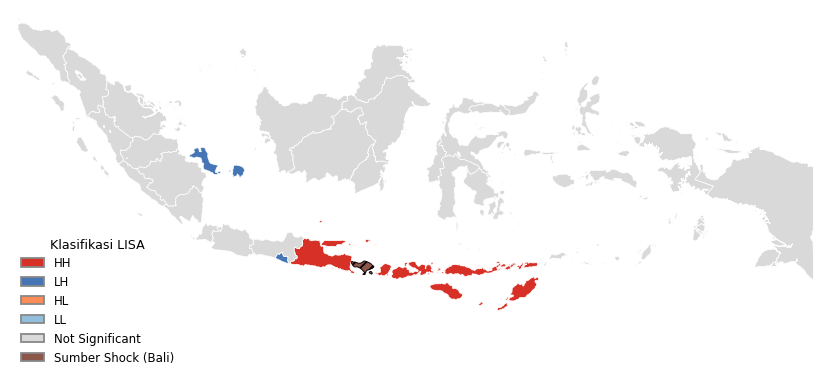

Gambar 3 tersimpan -> figur/4_5_02_peta_klaster_lisa.png | .pdf


In [ ]:
F_GEO = BASE + 'indonesia_prov.geojson'
if not os.path.exists(F_GEO):
    r = requests.get('https://raw.githubusercontent.com/ans-4175/peta-indonesia-geojson/'
                     'master/indonesia-prov.geojson', timeout=120)
    r.raise_for_status(); open(F_GEO, 'wb').write(r.content)

NAMA_GEOJSON = {'Aceh': 'DI. ACEH', 'Kep. Bangka Belitung': 'BANGKA BELITUNG',
                'Kep. Riau': 'KEPULAUAN RIAU', 'DI Yogyakarta': 'DAERAH ISTIMEWA YOGYAKARTA',
                'Nusa Tenggara Barat': 'NUSATENGGARA BARAT'}
gdf = gpd.read_file(F_GEO)
gdf['geometry'] = gdf.geometry.buffer(0)
kunci = {NAMA_GEOJSON.get(p, p.upper()): p for p in prov_list}
gdf['Provinsi'] = gdf['Propinsi'].str.upper().str.strip().map(kunci)
assert gdf['Provinsi'].notna().sum() == N_PROV, 'Ada provinsi yang belum cocok dengan GeoJSON'
gdf = gdf.dropna(subset=['Provinsi'])

gdf_sp = gdf.merge(df_sp[['Provinsi', 'Kuadran_Final', 'Intensitas', 'Local_I', 'p_value']],
                   on='Provinsi', how='left')
gdf_sp['Kuadran_Final'] = gdf_sp['Kuadran_Final'].fillna('Sumber Shock (Bali)')
WARNA = {**WARNA_KUADRAN, 'Sumber Shock (Bali)': C_BALI}
XLIM, YLIM = (94.8, 141.3), (-14.6, 6.4)

fig, ax = plt.subplots(figsize=(LEBAR, 82 * MM), layout='constrained')
for kuadran, warna in WARNA.items():
    sub = gdf_sp[gdf_sp['Kuadran_Final'] == kuadran]
    if len(sub) == 0:
        continue
    if kuadran == 'Sumber Shock (Bali)':
        sub.plot(ax=ax, color=warna, edgecolor='black', linewidth=0.5, hatch='////')
    else:
        sub.plot(ax=ax, color=warna, edgecolor='white', linewidth=0.4)
ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_aspect('equal'); ax.set_axis_off()
ax.legend(handles=[Patch(facecolor=c, edgecolor='#888888', label=k) for k, c in WARNA.items()],
          loc='lower left', fontsize=6.5, title='Klasifikasi LISA', title_fontsize=7)

simpan(fig, '4_5_02_peta_klaster_lisa', 'Klaster Spasial Intensitas Dampak Spillover (LISA)',
       sumber=SUMBER_IRIO + ' Batas wilayah: BAKOSURTANAL 1:250.000.',
       catatan='Signifikansi pada alpha=5%, 999 permutasi. Provinsi Bali ditandai terpisah sebagai wilayah asal shock.')

---
## Bagian 4 — Independensi Jaringan Struktural dan Jaringan Geografis

Sebelum kedua layer digabung, keduanya diuji independensinya. Jika keduanya berkorelasi kuat, layer geografis tidak menambah informasi baru di atas layer struktural yang sudah dibangun pada Tujuan 2. Pengujian dilakukan antara `Koef_Struktural_L` (jumlah blok invers Leontief yang menghubungkan provinsi dengan Bali) dan bobot geografis provinsi tersebut terhadap Bali pada matriks W.

Korelasi Spearman Struktural (L) vs Geografis (W): rho=0.4111, p=0.0175
-> Signifikan, korelasi lemah-sedang. Kedua layer sebagian tumpang tindih.


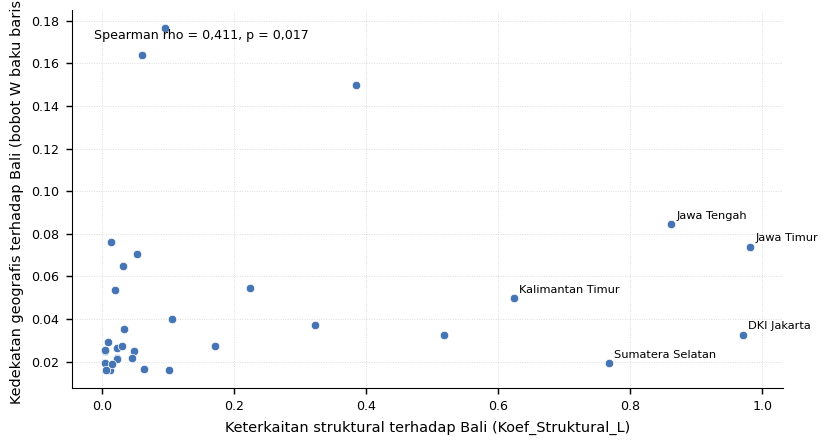

Gambar 4 tersimpan -> figur/4_5_03_uji_independensi.png | .pdf


In [ ]:
W_ke_bali = W[:, idx_bali]
df_uji = pd.DataFrame({
    'Provinsi': prov_list,
    'W_ke_Bali': W_ke_bali,
    'Koef_Struktural_L': df_e1.set_index('Provinsi').loc[prov_list, 'Koef_Struktural_L'].values,
}).query('Provinsi != @NAMA_BALI')

rho, p_val = stats.spearmanr(df_uji['Koef_Struktural_L'], df_uji['W_ke_Bali'])
print(f'Korelasi Spearman Struktural (L) vs Geografis (W): rho={rho:.4f}, p={p_val:.4f}')
if p_val < 0.05:
    kekuatan = 'kuat' if abs(rho) > 0.5 else 'lemah-sedang'
    print(f'-> Signifikan, korelasi {kekuatan}. Kedua layer sebagian tumpang tindih.')
else:
    print('-> Tidak signifikan pada level 5 persen, mendukung independensi kedua layer,')
    print('   sejalan dengan temuan Acemoglu, Akcigit, & Kerr (2016) pada level industri (rho 0,108-0,275).')

fig, ax = plt.subplots(figsize=(LEBAR, 85 * MM), layout='constrained')
ax.scatter(df_uji['Koef_Struktural_L'], df_uji['W_ke_Bali'], s=22, color='#4575b4',
           edgecolor='white', lw=0.4, zorder=3)
top5 = df_uji.reindex(df_uji['Koef_Struktural_L'].sort_values(ascending=False).index).head(5)
for _, r in top5.iterrows():
    ax.annotate(r['Provinsi'], (r['Koef_Struktural_L'], r['W_ke_Bali']), fontsize=6.3,
               xytext=(3, 3), textcoords='offset points')
ax.set_xlabel('Keterkaitan struktural terhadap Bali (Koef_Struktural_L)')
ax.set_ylabel('Kedekatan geografis terhadap Bali (bobot W baku baris)')
ax.text(0.03, 0.95, f'Spearman rho = {fmt(rho, 3)}, p = {fmt(p_val, 3)}', transform=ax.transAxes,
        va='top', fontsize=7)
ax.grid(ls=':', lw=0.5, alpha=0.5)

simpan(fig, '4_5_03_uji_independensi', 'Hubungan Keterkaitan Struktural dan Kedekatan Geografis terhadap Bali',
       catatan='Lima provinsi dengan keterkaitan struktural tertinggi diberi label. N=33 (Bali dikeluarkan).')

---
## Bagian 5 — Network Overlay

### 5.1 Tipologi provinsi: Exposure Struktural × Kuadran LISA

Setiap provinsi diklasifikasikan menurut keterkaitan strukturalnya (tinggi/rendah, dipisah pada median) dan kuadran LISA-nya. Tabel silang ini adalah bentuk *network overlay* itu sendiri: provinsi yang sama diposisikan sekaligus pada layer struktural dan layer spasial.

In [ ]:
df_sp['Koef_Struktural_L'] = df_sp['Provinsi'].map(df_e1.set_index('Provinsi')['Koef_Struktural_L'])
median_L = df_sp['Koef_Struktural_L'].median()
df_sp['Exposure_Struktural'] = np.where(df_sp['Koef_Struktural_L'] >= median_L, 'Tinggi', 'Rendah')

tabel_overlay = pd.crosstab(df_sp['Exposure_Struktural'], df_sp['Kuadran_Final'],
                            margins=True, margins_name='Total')
print('Tabel Overlay: Exposure Struktural x Kuadran LISA')
display(tabel_overlay)

kasus_struktural_murni = df_sp[(df_sp['Exposure_Struktural'] == 'Tinggi') &
                               (df_sp['Kuadran_Final'] == 'Not Significant')
                               ].sort_values('Koef_Struktural_L', ascending=False)
print('\\n=== Exposure struktural TINGGI, tapi TIDAK ada klaster spasial ===')
print('(dampak merambat murni lewat rantai produksi IRIO, bukan kedekatan geografis)')
display(kasus_struktural_murni[['Provinsi', 'Intensitas', 'Koef_Struktural_L', 'Kuadran_Final']])

kasus_geografis_murni = df_sp[(df_sp['Kuadran_Final'].isin(['HH', 'HL'])) &
                              (df_sp['Exposure_Struktural'] == 'Rendah')]
print('\\n=== Klaster spasial TINGGI (HH/HL), tapi exposure struktural RENDAH ===')
print('(dampak lebih didorong kedekatan geografis daripada keterkaitan produksi langsung)')
if len(kasus_geografis_murni):
    display(kasus_geografis_murni[['Provinsi', 'Intensitas', 'Koef_Struktural_L', 'Kuadran_Final']])
else:
    print('(tidak ada provinsi pada kategori ini)')

Tabel Overlay: Exposure Struktural x Kuadran LISA


Kuadran_Final,HH,LH,Not Significant,Total
Exposure_Struktural,,,,
Rendah,0,1,15,16
Tinggi,3,1,13,17
Total,3,2,28,33


\n=== Exposure struktural TINGGI, tapi TIDAK ada klaster spasial ===
(dampak merambat murni lewat rantai produksi IRIO, bukan kedekatan geografis)


,Provinsi,Intensitas,Koef_Struktural_L,Kuadran_Final
10,DKI Jakarta,0.062304,0.971083,Not Significant
12,Jawa Tengah,0.095740,0.861556,Not Significant
5,Sumatera Selatan,0.278141,0.768040,Not Significant
21,Kalimantan Timur,0.080132,0.623820,Not Significant
15,Banten,0.093736,0.518298,Not Significant
11,Jawa Barat,0.026783,0.385088,Not Significant
24,Sulawesi Tengah,0.049124,0.322370,Not Significant
25,Sulawesi Selatan,0.123747,0.224014,Not Significant
3,Riau,0.055452,0.171228,Not Significant
4,Jambi,0.051050,0.105703,Not Significant


\n=== Klaster spasial TINGGI (HH/HL), tapi exposure struktural RENDAH ===
(dampak lebih didorong kedekatan geografis daripada keterkaitan produksi langsung)
(tidak ada provinsi pada kategori ini)


### 5.2 Peta network overlay: klaster spasial dan jaringan spillover struktural

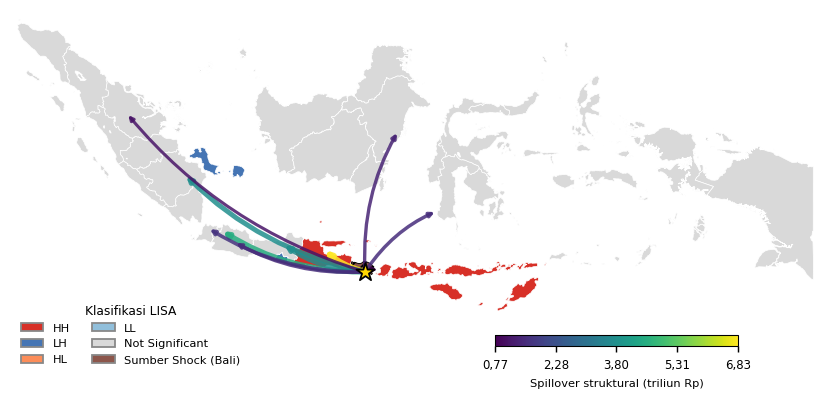

Gambar 5 tersimpan -> figur/4_5_04_network_overlay.png | .pdf


In [ ]:
df_edges_top = df_c1.sort_values('Spillover_triliun').head(10)
koord = df_e1.set_index('Provinsi')[['Lat', 'Lon']]
lat_bali, lon_bali = koord.loc[NAMA_BALI]

fig, ax = plt.subplots(figsize=(LEBAR, 82 * MM), layout='constrained')
for kuadran, warna in WARNA.items():
    sub = gdf_sp[gdf_sp['Kuadran_Final'] == kuadran]
    if len(sub) == 0:
        continue
    if kuadran == 'Sumber Shock (Bali)':
        sub.plot(ax=ax, color=warna, edgecolor='black', linewidth=0.5, hatch='////')
    else:
        sub.plot(ax=ax, color=warna, edgecolor='white', linewidth=0.4)
ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_aspect('equal'); ax.set_axis_off()

nilai = df_edges_top['Spillover_triliun'].abs()
norm = mcolors.Normalize(vmin=nilai.min(), vmax=nilai.max())
cmap = mpl.colormaps['viridis']
for _, row in df_edges_top.iterrows():
    prov = row['Provinsi']
    if prov not in koord.index:
        continue
    lat_p, lon_p = koord.loc[prov]
    v = abs(row['Spillover_triliun'])
    lebar = 0.5 + 3.0 * np.sqrt(v / nilai.max())
    ax.add_patch(FancyArrowPatch((lon_bali, lat_bali), (lon_p, lat_p), connectionstyle='arc3,rad=-0.15',
                                 arrowstyle='-|>', mutation_scale=5, lw=lebar,
                                 color=cmap(norm(v)), alpha=0.85, zorder=4))
ax.scatter(lon_bali, lat_bali, color='gold', s=110, marker='*', edgecolor='black', zorder=6)

cax = ax.inset_axes([0.60, 0.08, 0.30, 0.03])
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation='horizontal')
cb.set_label('Spillover struktural (triliun Rp)', fontsize=6.3)
atur_cbar_linier(cb, nilai.min(), nilai.max())

legend_elements = [Patch(facecolor=c, edgecolor='#888888', label=k) for k, c in WARNA.items()]
ax.legend(handles=legend_elements, loc='lower left', fontsize=6.3, ncol=2,
          title='Klasifikasi LISA', title_fontsize=6.8)

simpan(fig, '4_5_04_network_overlay',
       'Network Overlay: Keterkaitan Struktural (IRIO) dan Klaster Geografis (LISA)',
       sumber=SUMBER_IRIO + ' Batas wilayah: BAKOSURTANAL 1:250.000.',
       catatan='Sepuluh provinsi penerima spillover struktural terbesar ditampilkan sebagai panah dari Bali, '
               'warna busur menunjukkan besarnya spillover. Warna wilayah menunjukkan klaster LISA intensitas dampak.')

---
## Bagian 6 — Ekspor

In [ ]:
df_sp_out = df_sp[['Provinsi', 'Intensitas', 'Local_I', 'p_value', 'Kuadran_Final',
                   'Koef_Struktural_L', 'Exposure_Struktural']]

berkas = {
    'F1_LISA_Klasifikasi.csv': df_sp_out,
    'F2_Uji_Korelasi_Struktural_Geografis.csv': df_uji,
    'F3_Overlay_Struktural_LISA.csv': tabel_overlay.reset_index(),
    'F4_Daftar_Gambar.csv': pd.DataFrame(DAFTAR_GAMBAR),
}
for nama, d in berkas.items():
    d.to_csv(OUT_DIR + nama, index=False, encoding='utf-8-sig')

print(f'{len(berkas)} berkas CSV dan {len(DAFTAR_GAMBAR)} gambar tersimpan di:')
print(OUT_DIR)

print('\\nRingkasan untuk naskah:')
print(f"- Moran's I global (intensitas, N=33): {moran_global.I:.4f} (p={moran_global.p_sim:.3f})")
n_sig = (df_sp['Kuadran_Final'] != 'Not Significant').sum()
print(f'- Provinsi dengan klaster LISA signifikan: {n_sig} dari 33')
for k in ['HH', 'LH', 'HL', 'LL']:
    provs = df_sp.loc[df_sp['Kuadran_Final'] == k, 'Provinsi'].tolist()
    if provs:
        print(f'  {k}: {", ".join(provs)}')
print(f'- Korelasi struktural vs geografis: rho={rho:.4f}, p={p_val:.4f}')
print(f'- Kasus struktural murni (exposure tinggi, spasial tidak signifikan): {len(kasus_struktural_murni)} provinsi')

4 berkas CSV dan 5 gambar tersimpan di:
/content/drive/MyDrive/[01] Tugas-Atikah-STIS/[01] Skripsi Atikah/Data/09. Analisis Spatial+Network Overlay/
\nRingkasan untuk naskah:
- Moran's I global (intensitas, N=33): 0.0178 (p=0.119)
- Provinsi dengan klaster LISA signifikan: 5 dari 33
  HH: Jawa Timur, Nusa Tenggara Barat, Nusa Tenggara Timur
  LH: Kep. Bangka Belitung, DI Yogyakarta
- Korelasi struktural vs geografis: rho=0.4111, p=0.0175
- Kasus struktural murni (exposure tinggi, spasial tidak signifikan): 13 provinsi
